# Trying to figure out how PLsim works yay

In [3]:
# Importing the ncessary modules
from PLsim.otf import OTF
from PLsim.scene import Scene, SceneProjector
from PLsim.system.device import Device

import hcipy as hc
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Formatting the plots
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['figure.titlesize'] = 20
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.figsize'] = (10, 8)
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['figure.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.title_fontsize'] = 16
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['mathtext.fontset'] = 'cm'

## Setting up the mode-sorting device

### Define pupil grid

In [4]:
# Pixels in pupil grid (65 is enough for a 6-port PL)
ndim = 100

# Diameter of telescope aperture for pupil
diameter = 10 # [m]

# Create the pupil grid
pupil_grid = hc.make_pupil_grid(ndim, diameter)
print(pupil_grid)

CartesianGrid(RegularCoords)


### Plotting pupil grid

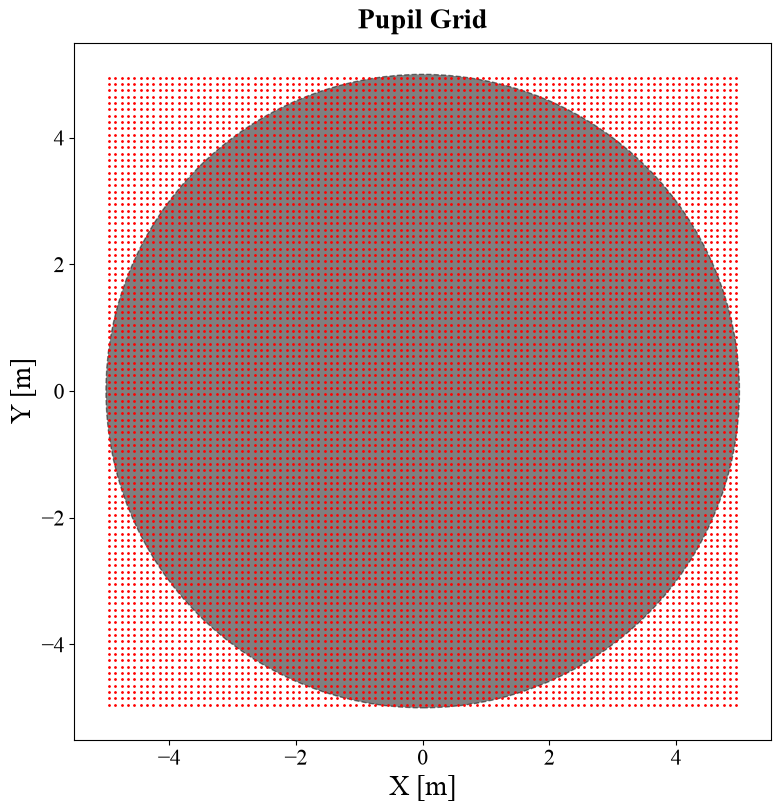

In [5]:
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Pupil Grid')

aperture_patch = patches.Circle((0, 0), diameter/2, fill=True, color='k', ls='--', alpha=0.5)
ax.add_patch(aperture_patch)

ax.scatter(pupil_grid.x, pupil_grid.y, c='r', s=1)

ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.set_aspect('equal')

plt.show()

### Define focal grid

In [6]:
# Resolution of focal grid (make sure this samples LP modes enough but also not truncate the outer parts)
focal_plane_resolution = 1e-6 # [m]

# Focal length of telescope (initial value, OTF.from_fiber_params will find an optimal focal ratio)
focal_length = 40 # [m]

# Create the focal grid
focal_grid = hc.make_pupil_grid(ndim, focal_plane_resolution * ndim)
print(focal_grid)

CartesianGrid(RegularCoords)


### Plotting focal grid

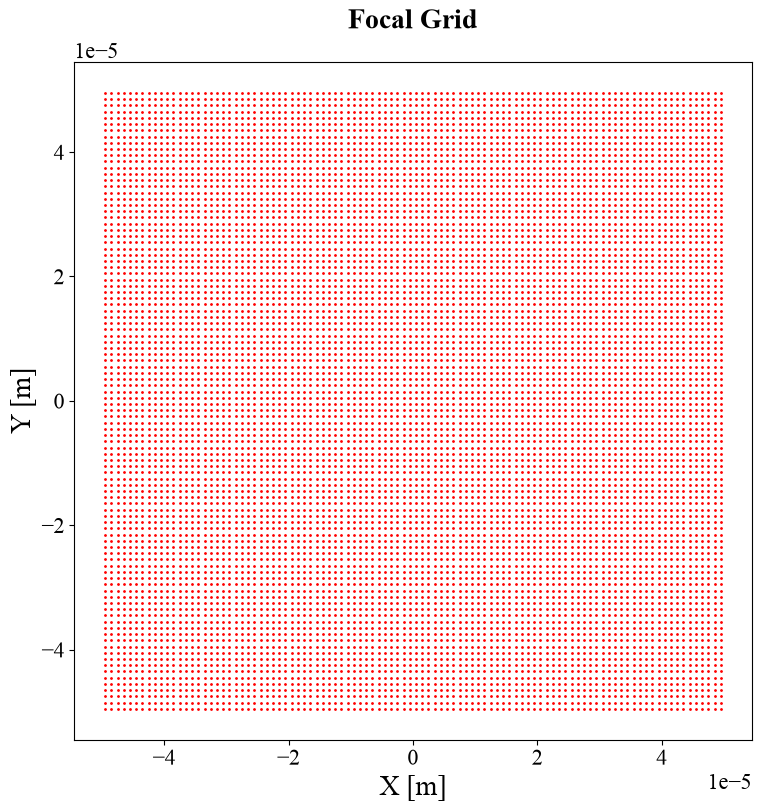

In [7]:
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Focal Grid')

ax.scatter(focal_grid.x, focal_grid.y, c='r', s=1)

ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.set_aspect('equal')

plt.show()

### Define PL multimode entrance parameters (changing this would change the number of guided modes)

In [8]:
# Index of refraction of the core
n_core = 1.444

# Index of refraction of the cladding
n_clad = 1.444 - 5.5e-3

# Core radius
r_core = 10e-6 # [m]

# Reference wavelength of light
ref_wavelength = 1.55e-6 # [m]

print(f'n_core: {n_core}')
print(f'n_clad: {n_clad}')
print(f'r_core: {r_core}')
print(f'ref_wavelength: {ref_wavelength}')

# Telescope aperture (circular) (a binary mask that has ones inside the aperture and zeros outside)
aperture = hc.make_circular_aperture(diameter)(pupil_grid)
print(aperture)

n_core: 1.444
n_clad: 1.4385
r_core: 1e-05
ref_wavelength: 1.55e-06
[0. 0. 0. ... 0. 0. 0.]


### Creating the optical transfer function (OTF)

In [9]:
otf = OTF.from_fiber_params(
    n_core, n_clad, r_core, ref_wavelength,
    focal_grid, pupil_grid,
    focal_length, aperture,
    optimize_focal_length=False
)
print(otf)

Supported modes:  ['LP01', 'LP11a', 'LP11b', 'LP21a', 'LP21b', 'LP02']
Number of modes:  6


### Viewing the focal plane modes
- Make sure the modes are not out of the focal grid
- Check for sampling

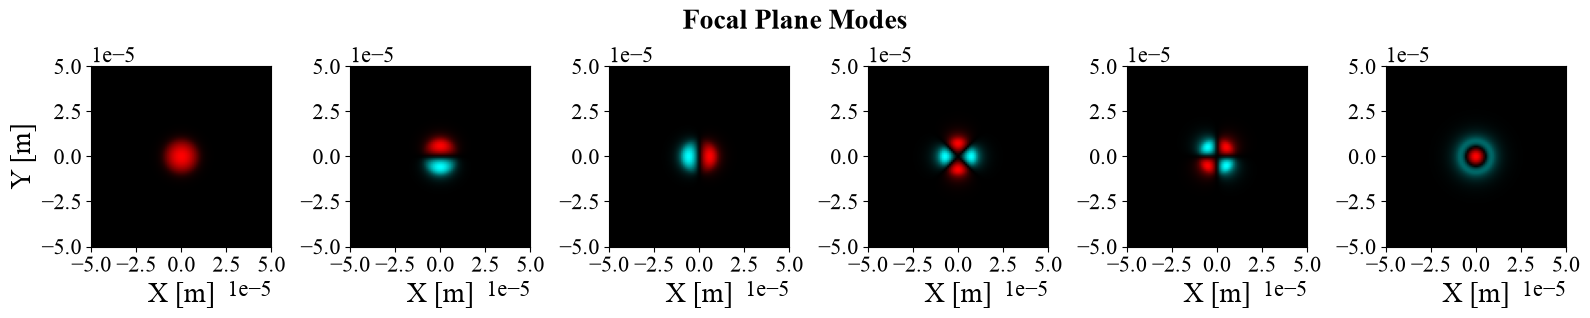

In [10]:
fig = plt.figure(figsize=(16,3))
axs = fig.subplots(ncols=6)

fig.suptitle('Focal Plane Modes')

for i in range(6):
    # Converts focal mode complex fields into color images
    hc.imshow_field(otf.focal_modes[i], grid=focal_grid, ax=axs[i])
    axs[i].set_xlabel('X [m]')

axs[0].set_ylabel('Y [m]')

fig.tight_layout()

plt.show()

### Compting the optical transfer function matrix
This computation may be slow if `ndim` is too large or the number of modes is big

In [11]:
otf.compute()

### Now setting up the photonic device using `Device`:
- Use a certain number of wavelength channels (n_wav)
- Will calculate the transfer matrix (dimensions of n_wav $\times$ n_outputs $\times$ n_modes)
- Assume a very narrow bandwidth so that the OTF does not change with wavelength

In [12]:
# Importing the function for generating a unitary matrix
from PLsim.system.lantern import generate_unitary_matrix

# Define number of wavelength channels
n_wav = 21

# Initializing matrix (complex)
matrix = generate_unitary_matrix(6)[np.newaxis, :, :].repeat(n_wav, axis=0)
print(matrix.shape)

# Initializing device with the unitary matrix
device = Device(matrix)

(21, 6, 6)
Device initialized with:
  Lantern matrices: (21, 6, 6)
  PIC matrices: None
  Wavelengths: 21


## Creating the input scene

### Define the `Scene` object to calculate mutual coherence functions, and the `SceneProjector` object that projects the mutual coherence functions onto the OTFs

In [13]:
# Defining scene
scene = Scene(pupil_grid, ref_wavelength)

# Creating a projection onto the OTF
scene_projector = SceneProjector(otf, scene)

### Make an input scene as a function of wavelength
- Binary star, with one star having a deep absorption line

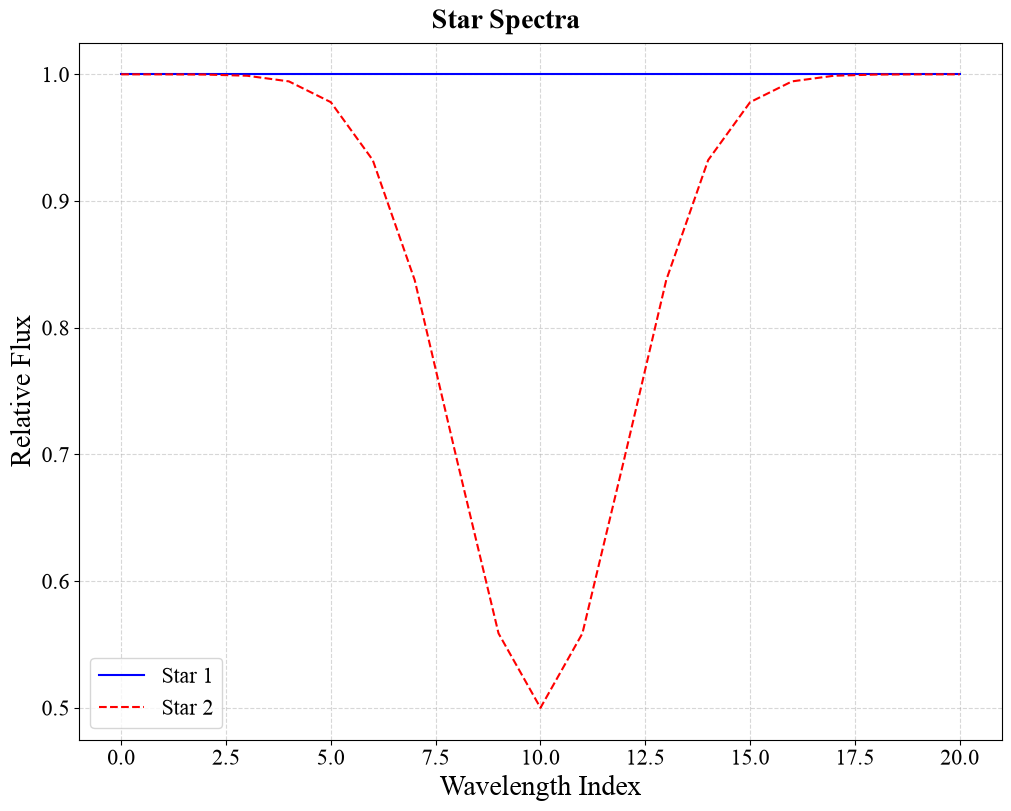

In [14]:
# Differnet indices for the wavelength channels
wavelength_indices = np.arange(n_wav)

# Initializing spectra for the two stars
star1_spectrum = np.ones(n_wav)
star2_spectrum = np.ones(n_wav)

# Central wavelength of the entire spectrum
central_wavelength = n_wav // 2

# Width of the center absorption line
line_width = 2 # channels

# Initializing the spectrum of star 2 (relative flux to star 1, assuming Gaussian line)
star2_spectrum -= 0.5 * np.exp(-0.5 * (wavelength_indices - central_wavelength)**2 / line_width**2)

# Plotting the spectra
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Star Spectra')

ax.plot(wavelength_indices, star1_spectrum, label='Star 1', color='b', linestyle='-')
ax.plot(wavelength_indices, star2_spectrum, label='Star 2', color='r', linestyle='--')

ax.set_xlabel('Wavelength Index')
ax.set_ylabel('Relative Flux')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend()

plt.show()

### For binaries, simply compute responses for two positions and combine them

In [15]:
star1_x, star1_y = 0, 0 # mas, mas
star2_x, star2_y = 15, 0 # mas, mas

star1_x *= 1e-3/206265 # converting to radians
star1_y *= 1e-3/206265 # converting to radians
star2_x *= 1e-3/206265 # converting to radians
star2_y *= 1e-3/206265 # converting to radians

# Calculate the projected fields for the two stars
star1_projected = scene_projector.compute_point(star1_x, star1_y).repeat(n_wav, axis=2) * star1_spectrum[np.newaxis, np.newaxis]
print(star1_projected.shape)
star2_projected = scene_projector.compute_point(star2_x, star2_y).repeat(n_wav, axis=2) * star2_spectrum[np.newaxis, np.newaxis]
print(star2_projected.shape)

# Combine the projected fields
combined = star1_projected + star2_projected

(6, 6, 21)
(6, 6, 21)


## 3. Simulate the spectra through the photonic lantern device

### Pass the spectra through the device

In [16]:
out_spectra = device.calculate_outputs(combined.transpose(2, 0, 1))

### Plotting the combined result after passing through the device

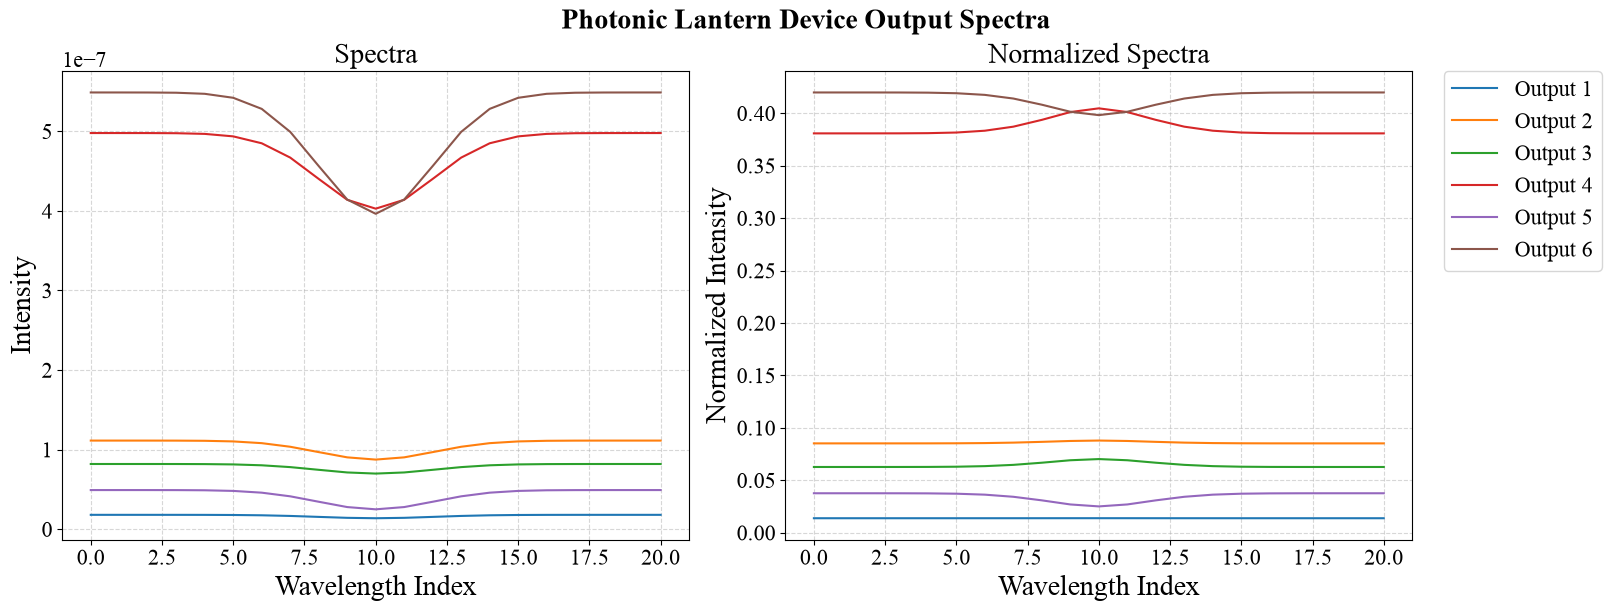

In [17]:
fig = plt.figure(figsize=(16, 6))
fig.set_constrained_layout(True)
axes = fig.subplots(ncols=2)

fig.suptitle('Photonic Lantern Device Output Spectra')

for i in range(6):
    axes[0].plot(out_spectra[:, i])
    axes[1].plot(out_spectra[:, i]/np.sum(out_spectra, axis=1), label=f'Output {i+1}')

axes[0].set_title('Spectra')
axes[1].set_title('Normalized Spectra')
axes[0].set_xlabel('Wavelength Index')
axes[1].set_xlabel('Wavelength Index')
axes[0].set_ylabel('Intensity')
axes[1].set_ylabel('Normalized Intensity')

axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

axes[0].grid(True, linestyle='--', alpha=0.5)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.show()

### How does the PL output change with position of sources?

Normalized intensities:
Output 1: 0.013910987665946043
Output 2: 0.09305457725696574
Output 3: 0.0846461760835118
Output 4: 0.45040746258367453
Output 5: 0.0010996704509767118
Output 6: 0.35688112595892535


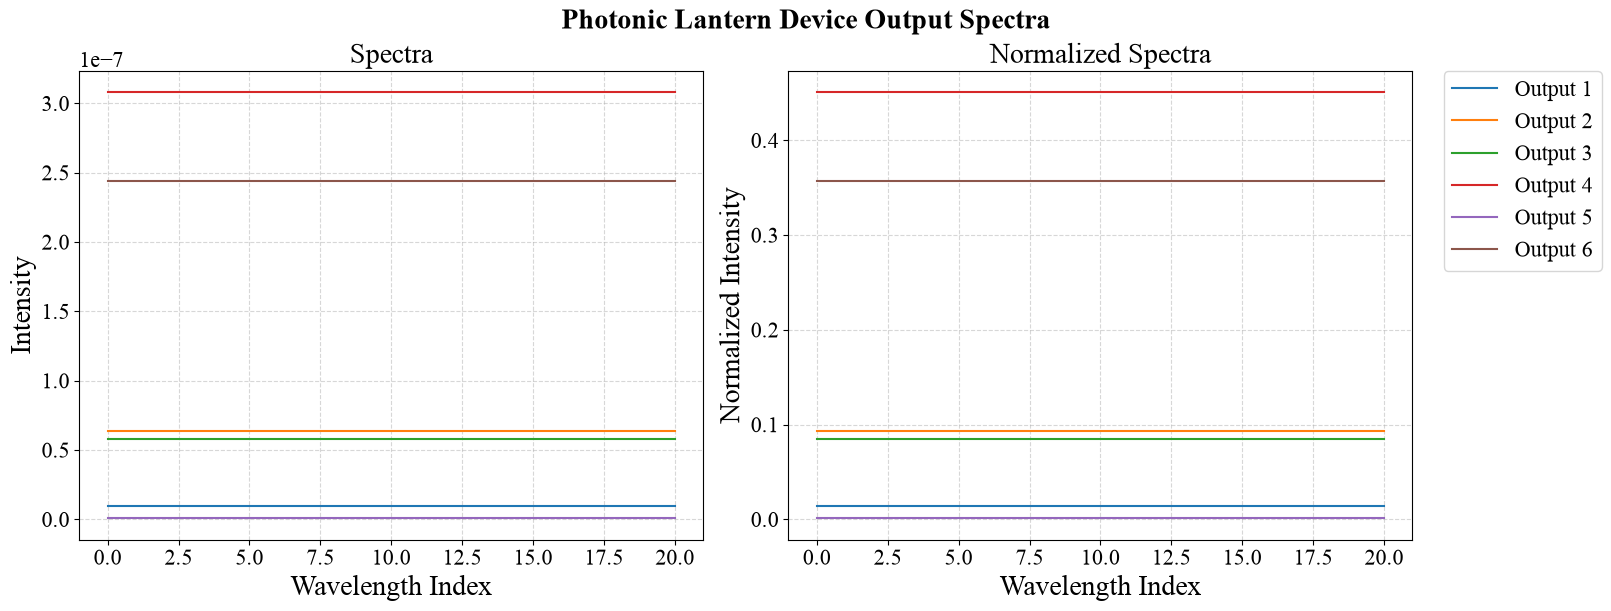

In [18]:
# Creating a single source and moving it around
star1_x, star1_y = 0, 0 # mas, mas

star1_x *= 1e-3/206265 # converting to radians
star1_y *= 1e-3/206265 # converting to radians

star1_projected = scene_projector.compute_point(star1_x, star1_y).repeat(n_wav, axis=2) * star1_spectrum[np.newaxis, np.newaxis]
out_spectra = device.calculate_outputs(star1_projected.transpose(2, 0, 1))

intensity = []

print('Normalized intensities:')
for i in range(6):
    print(f'Output {i+1}: {np.mean(out_spectra[:, i] / np.sum(out_spectra, axis=1))}')
    intensity.append(np.mean(out_spectra[:, i] / np.sum(out_spectra, axis=1)))

fig = plt.figure(figsize=(16, 6))
fig.set_constrained_layout(True)
axes = fig.subplots(ncols=2)

fig.suptitle('Photonic Lantern Device Output Spectra')

for i in range(6):
    axes[0].plot(out_spectra[:, i])
    axes[1].plot(out_spectra[:, i]/np.sum(out_spectra, axis=1), label=f'Output {i+1}')

axes[0].set_title('Spectra')
axes[1].set_title('Normalized Spectra')
axes[0].set_xlabel('Wavelength Index')
axes[1].set_xlabel('Wavelength Index')
axes[0].set_ylabel('Intensity')
axes[1].set_ylabel('Normalized Intensity')

axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

axes[0].grid(True, linestyle='--', alpha=0.5)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.show()

### For reference: focal plane modes

Max: 0.08955525395320885, Min: 4.503601715658945e-15, Sum: 19.254472032408607
Max: 0.09312056986138142, Min: -0.09312056986138142, Sum: 1.7763568394002505e-15
Max: 0.09312056986138144, Min: -0.09312056986138144, Sum: 1.407984222342605e-15
Max: 0.08890680850301803, Min: -0.08890680850301803, Sum: -1.97758476261356e-16
Max: 0.08881089495411952, Min: -0.08881089495411952, Sum: 4.680365253348362e-17
Max: 0.12257908003663515, Min: -0.05061319792646624, Sum: -16.31228317545037


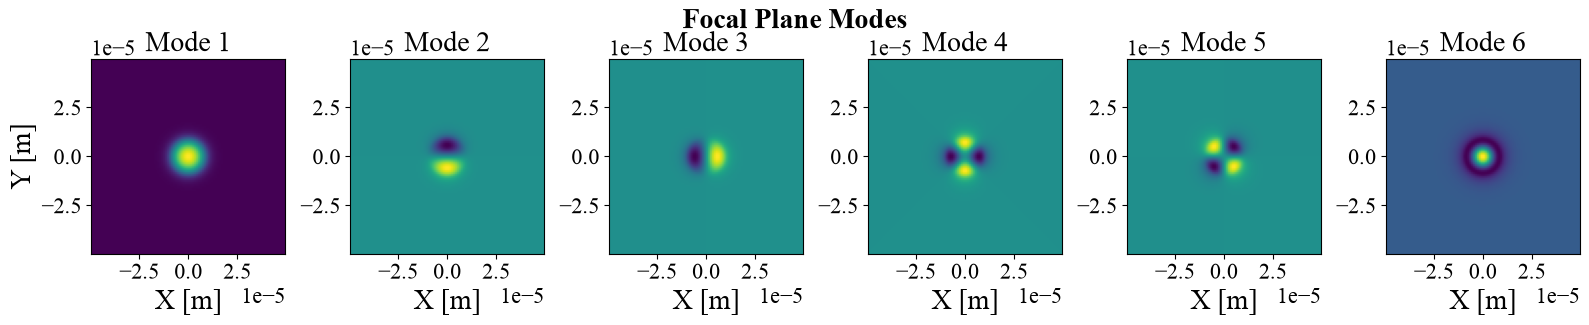

In [19]:
fig = plt.figure(figsize=(16,3))
axs = fig.subplots(ncols=6)

fig.suptitle('Focal Plane Modes')

modes = []

for i in range(6):
    axs[i].set_title(f'Mode {i+1}')

    field = np.real(otf.focal_modes[i].reshape(ndim, ndim))
    modes.append(field)
    
    axs[i].imshow(field, extent=[focal_grid.x[0], focal_grid.x[-1], focal_grid.y[0], focal_grid.y[-1]])
    
    axs[i].set_xlabel('X [m]')

    print(f'Max: {np.max(field)}, Min: {np.min(field)}, Sum: {np.sum(field)}')

axs[0].set_ylabel('Y [m]')

fig.tight_layout()

plt.show()

### Reconstructing image using modes and intensities

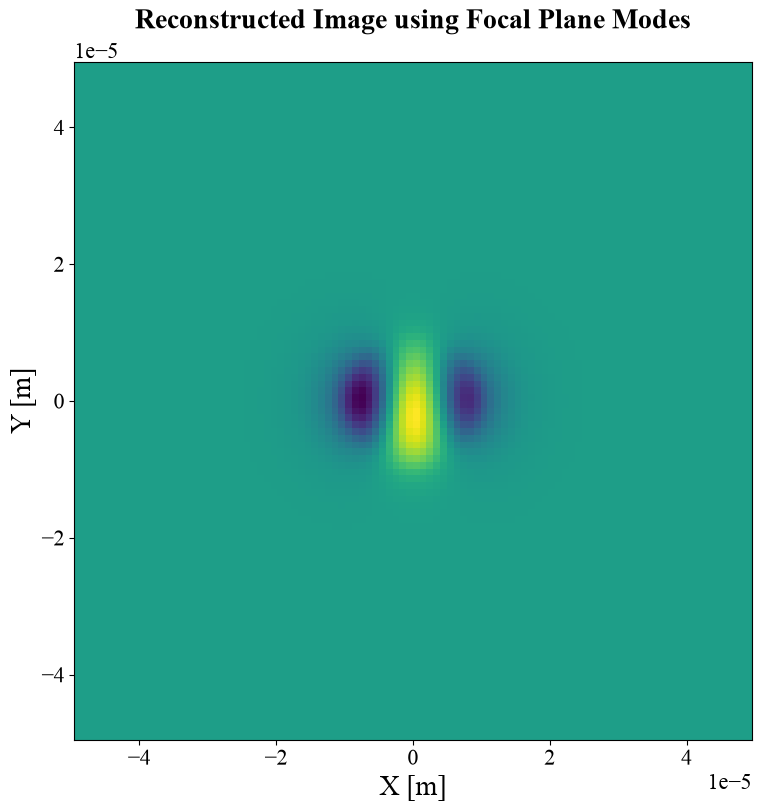

In [20]:
reconstructed_image = np.zeros((ndim, ndim))

for i in range(6):
    reconstructed_image += modes[i] * intensity[i]

fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Reconstructed Image using Focal Plane Modes')

ax.imshow(reconstructed_image, extent=[focal_grid.x[0], focal_grid.x[-1], focal_grid.y[0], focal_grid.y[-1]])

ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')

plt.show()

### Iterating over a group of star X positions to see how the intensities at each output change

(100, 6)


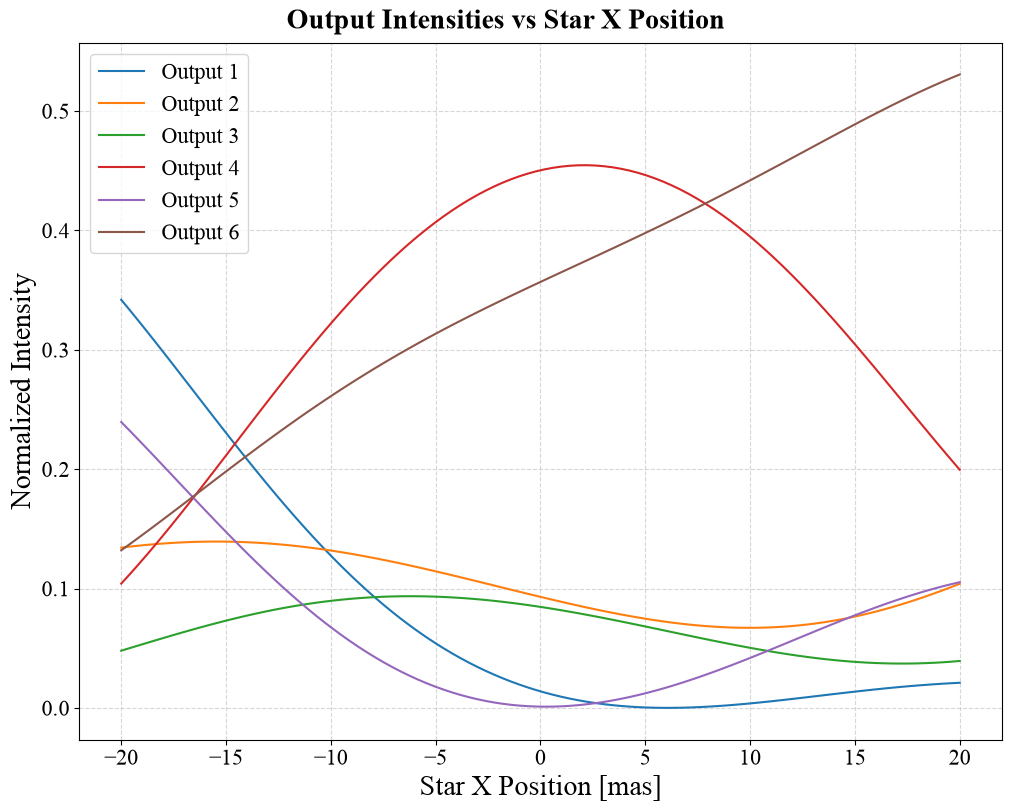

In [21]:
# Moving the star around
star1_x_mas = np.linspace(-20, 20, 100) # mas
star1_y_mas = np.zeros_like(star1_x_mas) # mas

star1_x_rad = star1_x_mas * 1e-3/206265 # converting to radians
star1_y_rad = star1_y_mas * 1e-3/206265 # converting to radians

normalized_intensities = []

for i, x in enumerate(star1_x_rad):
    star1_projected = scene_projector.compute_point(x, star1_y_rad[i]).repeat(n_wav, axis=2) * star1_spectrum[np.newaxis, np.newaxis]
    out_spectra = device.calculate_outputs(star1_projected.transpose(2, 0, 1))

    constant_star_pos = []
    for output in range(6):
        constant_star_pos.append(np.mean(out_spectra[:, output] / np.sum(out_spectra, axis=1)))

    normalized_intensities.append(constant_star_pos)

normalized_intensities = np.array(normalized_intensities)
print(normalized_intensities.shape)

fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Output Intensities vs Star X Position')

for i in range(6):
    ax.plot(star1_x_mas, normalized_intensities[:, i], label=f'Output {i+1}')

ax.set_xlabel('Star X Position [mas]')
ax.set_ylabel('Normalized Intensity')

ax.legend()

ax.grid(True, linestyle='--', alpha=0.5)

plt.show()
